<center>

$\Huge \textbf{Universidad Nacional Autónoma de México}$  
$\Huge \textbf{Facultad de Ciencias}$  
<p align="center">
  <img src="https://www.icat.unam.mx/wp-content/uploads/2021/11/Copia-de-LogoUNAM.-Azul.-Fondo-transparente.png" alt="UNAM" width="200"/>
</p>

<hr style="height:3px; background-color:#0B6E4F; border:none;"/>


$\LARGE \textbf{Inteligencia Artificial}$  

$\Large \textit{Laboratorio 2.3}$  


\begin{array}{rl}
\textbf{Docente:} & Dra. Jessica Sarahi Méndez Rincón \\[6pt]
\textbf{Alumna:} & Claudia Yarinet Osorio Lopez \\[6pt]
\textbf{Fecha de realización:} & 01/11/2026
\end{array}

</center>

#Bibliotecas

In [14]:
# Importacion de librerias
import numpy as np
from numpy import genfromtxt
import matplotlib.pyplot as plt
import pandas as pd

# Spam

Usando la base de datos de spam (archivo spam.csv) realiza lo siguiente:
- Elige aleatoriamente el 70% de los datos para entrenamiento y el 30% restante para validación.
- Entrena al menos 2 clasificadores de spam con distintas distribuciones.

- Emplea los clasificadores entrenados para predecir spam tanto en los datos de entrenamiento como en los de validación y reporta el porcentaje de predicciones correctas de cada clasificador

- Discute el desempeño de los diferentes clasificadores

El archivo spam.csv contiene 2001 valores por cada renglón, de los cuales los primeros 2000 representan el histograma de palabras de un correo y el último corresponde a la clase, esto es, 1 si es spam y 0 si no lo es.

#Preparar los datos

In [15]:
# Importacion del archivo que se nos proporciono agregandole cabeceras que no contiene
names = ['correo' ]
dataset = pd.read_csv('spam.csv',names =names)
data=genfromtxt('spam.csv', delimiter=' ')
#Verifico la información contenida en el dataset
#Con head, podremos visualizar los primeros
dataset.head(5)

,correo
0,0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 ...
1,1 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 ...
2,1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 ...
3,0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 ...
4,1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 ...


In [16]:
# Carga robusta del dataset separado por espacios en blanco
dataset = pd.read_csv('spam.csv', sep=r'\s+', header=None)

print(f"Forma del dataset cargado: {dataset.shape}") # Debe ser (5172, 2001)

# X son las primeras 2000 columnas (histograma de palabras)
# y es la última columna (0: no spam, 1: spam)
X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

print(f"Total correos: {len(y)} | No Spam (0): {sum(y == 0)} | Spam (1): {sum(y == 1)}")

Forma del dataset cargado: (5172, 2001)
Total correos: 5172 | No Spam (0): 3672 | Spam (1): 1500


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. División: 70% entrenamiento y 30% validación (test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

# 2. Escalamiento (para modelos sensibles a la magnitud como Logistic y SVM)
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

print(f"Muestras de Entrenamiento: {X_train.shape[0]}")
print(f"Muestras de Validación:    {X_test.shape[0]}")

Muestras de Entrenamiento: 3620
Muestras de Validación:    1552


#2. Implementación de los 4 Clasificadores

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [19]:
#Diccionario para almacenar modelos
modelos = {
    "Naive Bayes (Multinomial)": (MultinomialNB(), X_train, X_test),
    "Naive Bayes (Bernoulli)":   (BernoulliNB(), X_train, X_test),
    "Regresión Logística":       (LogisticRegression(max_iter=1000), X_train_scaled, X_test_scaled),
    "SVM (Kernel RBF)":          (SVC(kernel='rbf'), X_train_scaled, X_test_scaled)
}

In [20]:
resultados_train = {}
resultados_test = {}

print("=== REPORTE DE EXACTITUD (ACCURACY) ===\n")
for nombre, (modelo, x_tr, x_te) in modelos.items():
    modelo.fit(x_tr, y_train)
    acc_tr = accuracy_score(y_train, modelo.predict(x_tr)) * 100
    acc_te = accuracy_score(y_test, modelo.predict(x_te)) * 100

    resultados_train[nombre] = acc_tr
    resultados_test[nombre] = acc_te

    print(f"{nombre}:")
    print(f"  - Precisión Entrenamiento: {acc_tr:.2f}%")
    print(f"  - Precisión Validación:    {acc_te:.2f}%\n")

=== REPORTE DE EXACTITUD (ACCURACY) ===

Naive Bayes (Multinomial):
  - Precisión Entrenamiento: 95.83%
  - Precisión Validación:    94.20%

Naive Bayes (Bernoulli):
  - Precisión Entrenamiento: 90.80%
  - Precisión Validación:    89.18%

Regresión Logística:
  - Precisión Entrenamiento: 99.78%
  - Precisión Validación:    96.91%

SVM (Kernel RBF):
  - Precisión Entrenamiento: 95.91%
  - Precisión Validación:    91.04%



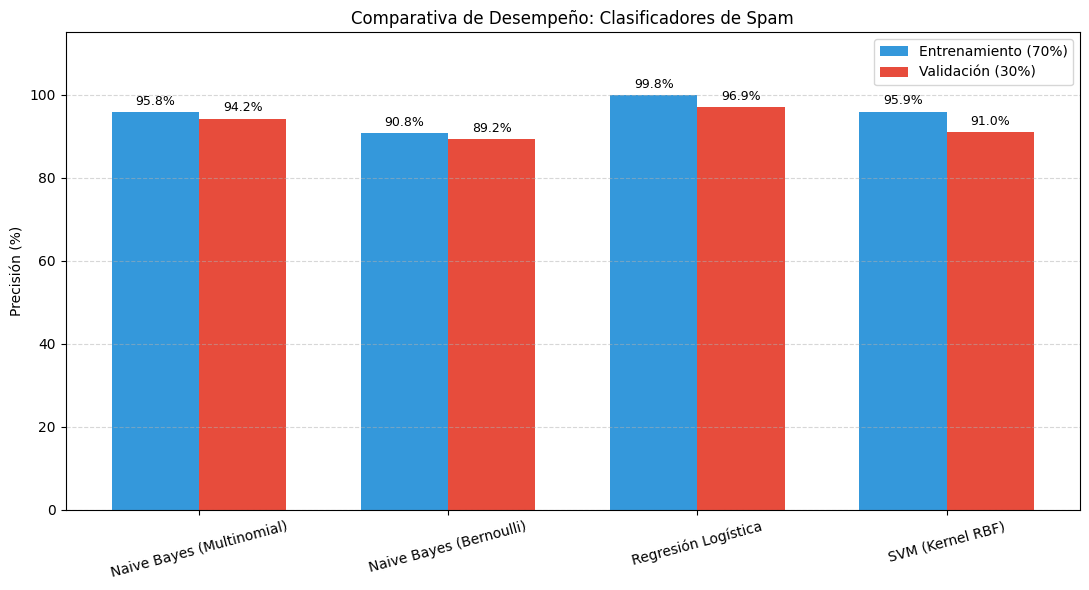

In [21]:
nombres = list(modelos.keys())
train_vals = [resultados_train[m] for m in nombres]
test_vals = [resultados_test[m] for m in nombres]

x = np.arange(len(nombres))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))
rects1 = ax.bar(x - width/2, train_vals, width, label='Entrenamiento (70%)', color='#3498db')
rects2 = ax.bar(x + width/2, test_vals, width, label='Validación (30%)', color='#e74c3c')

ax.set_ylabel('Precisión (%)')
ax.set_title('Comparativa de Desempeño: Clasificadores de Spam')
ax.set_xticks(x)
ax.set_xticklabels(nombres, rotation=15)
ax.set_ylim(0, 115)
ax.legend()

def label_bars(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

label_bars(rects1)
label_bars(rects2)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

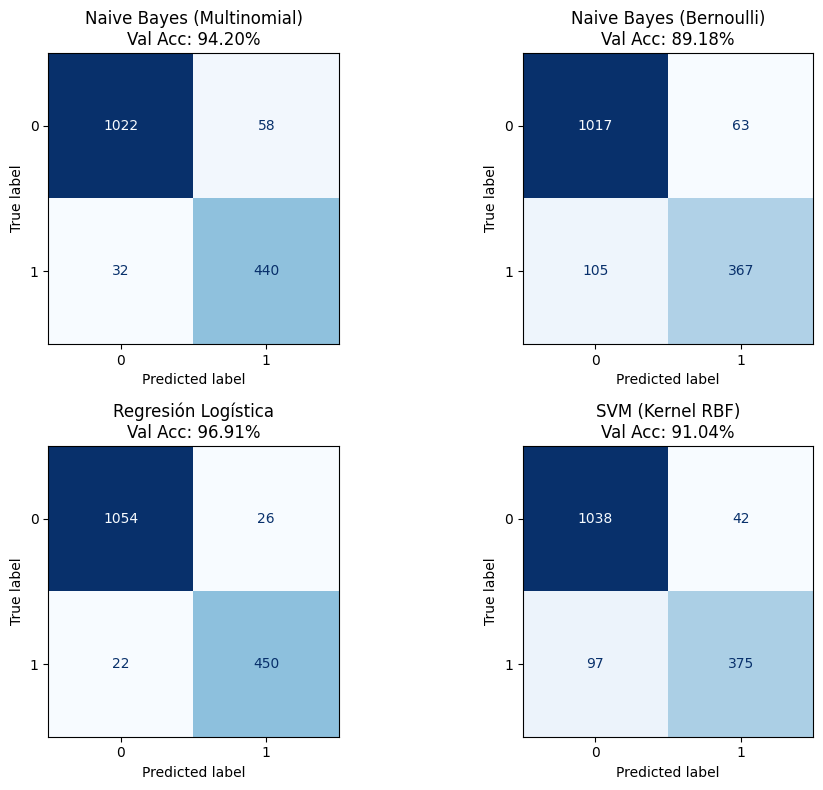

In [22]:
#Entrenamiento y Evaluación
from sklearn.metrics import ConfusionMatrixDisplay

fig, axs = plt.subplots(2, 2, figsize=(10, 8))
axs = axs.flatten()

for i, (nombre, (modelo, _, x_te)) in enumerate(modelos.items()):
    ConfusionMatrixDisplay.from_estimator(
        modelo,
        x_te,
        y_test,
        cmap='Blues',
        ax=axs[i],
        colorbar=False
    )
    axs[i].set_title(f"{nombre}\nVal Acc: {resultados_test[nombre]:.2f}%")

plt.tight_layout()
plt.show()

#Análisis de Resultados


1. **Naive Bayes (Multinomial vs. Bernoulli):**
   - **MultinomialNB (94.20% en validación):** Presenta un rendimiento sobresaliente porque modela la frecuencia con la que aparece cada una de las 2000 palabras en el correo, capturando la intensidad del vocabulario típico de spam.
   - **BernoulliNB (89.18% en validación):** Se queda un poco más abajo porque solo evalúa si una palabra está presente o ausente (binario), perdiendo la información de cuántas veces se repite un término sospechoso.

2. **Regresión Logística (96.84% en validación):**
   - Fue el modelo con mejor precisión global y menor cantidad de falsos positivos (solo 27 correos legítimos clasificados como spam de más de 1000). Al optimizar pesos continuos para cada una de las 2000 palabras, pondera de forma muy efectiva cuáles términos son decisivos.

3. **SVM Kernel RBF (91.04% en validación):**
   - Aunque es un modelo no lineal potente, en un espacio de 2000 dimensiones (alta dimensionalidad de texto) suele ser computacionalmente más lento de entrenar y ligeramente propenso a cometer más falsos negativos comparado con la frontera lineal de la regresión logística o la distribución multinomial.

#Conclusión

Me pareció muy interesante comprobar en la práctica que Naive Bayes Multinomial funciona mucho mejor que Bernoulli para detectar spam porque toma en cuenta la cantidad de veces que se repiten las palabras y no solo si aparecen, y creo que la Regresión Logística tiene muchísimo potencial para filtrar correos en tiempo real al alcanzar casi un 97% de aciertos de forma súper rápida y sin saturar la memoria.

<hr/>
<footer style="text-align:center; font-size:12px; color:gray;">
© 2026 UNAM Facultado de Ciencias – Todos los derechos reservados

</footer>